In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/dataset/uk_retail_abc_practice_dataset.csv', encoding='latin1')

# ***Investigating the data***

In [ ]:
df.shape

(100, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Product_ID              100 non-null    object 
 1   Product_Name            100 non-null    object 
 2   Category                100 non-null    object 
 3   Annual_Units_Sold       100 non-null    int64  
 4   Unit_Selling_Price_GBP  100 non-null    float64
dtypes: float64(1), int64(1), object(3)
memory usage: 4.0+ KB


In [ ]:
df.head()

,Product_ID,Product_Name,Category,Annual_Units_Sold,Unit_Selling_Price_GBP
0,P001,Milk 2L,Dairy,499,2.29
1,P002,Semi-skimmed Milk 1L,Dairy,2970,2.80
2,P003,Cheddar Cheese 400g,Dairy,394,0.83
3,P004,Greek Yogurt 500g,Dairy,958,2.12
4,P005,Butter 250g,Dairy,591,1.98


In [ ]:
df.isnull().sum()

,0
Product_ID,0
Product_Name,0
Category,0
Annual_Units_Sold,0
Unit_Selling_Price_GBP,0


In [ ]:
df["Annual_Revenue_GBP"] = (
    df["Annual_Units_Sold"] *
    df["Unit_Selling_Price_GBP"]
)

display(df.head())

,Product_ID,Product_Name,Category,Annual_Units_Sold,Unit_Selling_Price_GBP,Annual_Revenue_GBP
0,P001,Milk 2L,Dairy,499,2.29,1142.71
1,P002,Semi-skimmed Milk 1L,Dairy,2970,2.80,8316.00
2,P003,Cheddar Cheese 400g,Dairy,394,0.83,327.02
3,P004,Greek Yogurt 500g,Dairy,958,2.12,2030.96
4,P005,Butter 250g,Dairy,591,1.98,1170.18


# ***Calculate ABC Analysis***

In [ ]:
# Rank products by annual revenue
df = df.sort_values(
    by="Annual_Revenue_GBP",
    ascending=False
).reset_index(drop=True)

display(
    df[["Product_Name", "Annual_Revenue_GBP"]].head(10)
)


,Product_Name,Annual_Revenue_GBP
0,Garden Gloves,237019.44
1,Microfibre Cloths 5pk,23896.08
2,Frozen Berries 500g,18327.15
3,Pork Sausages 8pk,17192.61
4,Sunscreen SPF 30,17141.64
5,Instant Noodles 5pk,13550.25
6,Beef Mince 500g,11140.44
7,AA Batteries 8pk,10557.56
8,Ready Meal Lasagne,10458.15
9,Tea Bags 160pk,10205.10


In [ ]:
# Calculate each product's contribution
total_revenue = df["Annual_Revenue_GBP"].sum()

df["Revenue_Contribution_%"] = (
    df["Annual_Revenue_GBP"] / total_revenue * 100
)

df["Cumulative_Revenue_%"] = (
    df["Revenue_Contribution_%"].cumsum()
)

print("Total annual revenue: £{:,.2f}".format(total_revenue))

display(
    df[[
        "Product_Name",
        "Annual_Revenue_GBP",
        "Revenue_Contribution_%",
        "Cumulative_Revenue_%"
    ]].head(15).round(2)
)


Total annual revenue: £673,553.53


,Product_Name,Annual_Revenue_GBP,Revenue_Contribution_%,Cumulative_Revenue_%
0,Garden Gloves,237019.44,35.19,35.19
1,Microfibre Cloths 5pk,23896.08,3.55,38.74
2,Frozen Berries 500g,18327.15,2.72,41.46
3,Pork Sausages 8pk,17192.61,2.55,44.01
4,Sunscreen SPF 30,17141.64,2.54,46.56
5,Instant Noodles 5pk,13550.25,2.01,48.57
6,Beef Mince 500g,11140.44,1.65,50.22
7,AA Batteries 8pk,10557.56,1.57,51.79
8,Ready Meal Lasagne,10458.15,1.55,53.34
9,Tea Bags 160pk,10205.10,1.52,54.86


Revenue_Contribution_%: the percentage of total revenue contributed by one product.



Cumulative_Revenue_%: the running total of those percentages from the highest-revenue product downward.

# ***Assign A, B and C categories***

Category	Cumulative revenue contribution	Typical priority

A	Up to 80% --	Highest

B	Above 80% to 95%--	Medium

C	Above 95% --	Lower

In [ ]:

def assign_abc(cumulative_pct):
    if cumulative_pct <= 80:
        return "A"
    elif cumulative_pct <= 95:
        return "B"
    else:
        return "C"

df["ABC_Category"] = (
    df["Cumulative_Revenue_%"].apply(assign_abc)
)

display(
    df[[
        "Product_Name",
        "Annual_Revenue_GBP",
        "Cumulative_Revenue_%",
        "ABC_Category"
    ]].head(20).round(2)
)


,Product_Name,Annual_Revenue_GBP,Cumulative_Revenue_%,ABC_Category
0,Garden Gloves,237019.44,35.19,A
1,Microfibre Cloths 5pk,23896.08,38.74,A
2,Frozen Berries 500g,18327.15,41.46,A
3,Pork Sausages 8pk,17192.61,44.01,A
4,Sunscreen SPF 30,17141.64,46.56,A
5,Instant Noodles 5pk,13550.25,48.57,A
6,Beef Mince 500g,11140.44,50.22,A
7,AA Batteries 8pk,10557.56,51.79,A
8,Ready Meal Lasagne,10458.15,53.34,A
9,Tea Bags 160pk,10205.10,54.86,A


# ***Summary of the ABC categories***

In [ ]:

abc_summary = (
    df.groupby("ABC_Category")
      .agg(
          Product_Count=("Product_ID", "count"),
          Total_Revenue=("Annual_Revenue_GBP", "sum")
      )
)

abc_summary["Product_Share_%"] = (
    abc_summary["Product_Count"] / len(df) * 100
)

abc_summary["Revenue_Share_%"] = (
    abc_summary["Total_Revenue"] / total_revenue * 100
)

abc_summary = abc_summary.reindex(["A", "B", "C"])

display(abc_summary.round(2))


,Product_Count,Total_Revenue,Product_Share_%,Revenue_Share_%
ABC_Category,,,,
A,36,538635.92,36.0,79.97
B,34,100818.55,34.0,14.97
C,30,34099.06,30.0,5.06


Visualise the findings

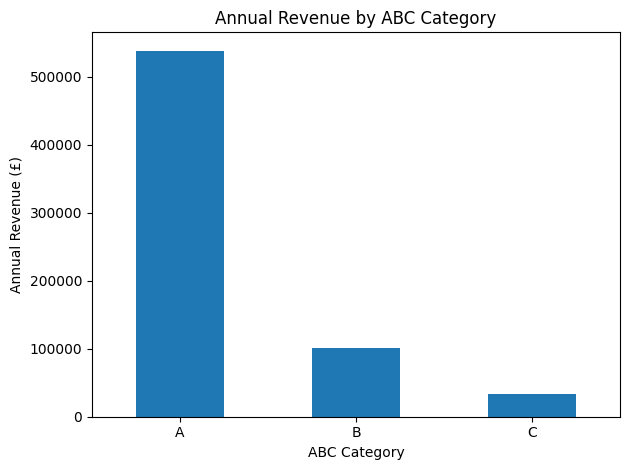

In [ ]:
# Revenue by ABC category
abc_summary["Total_Revenue"].plot(
    kind="bar",
    title="Annual Revenue by ABC Category",
    xlabel="ABC Category",
    ylabel="Annual Revenue (£)"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


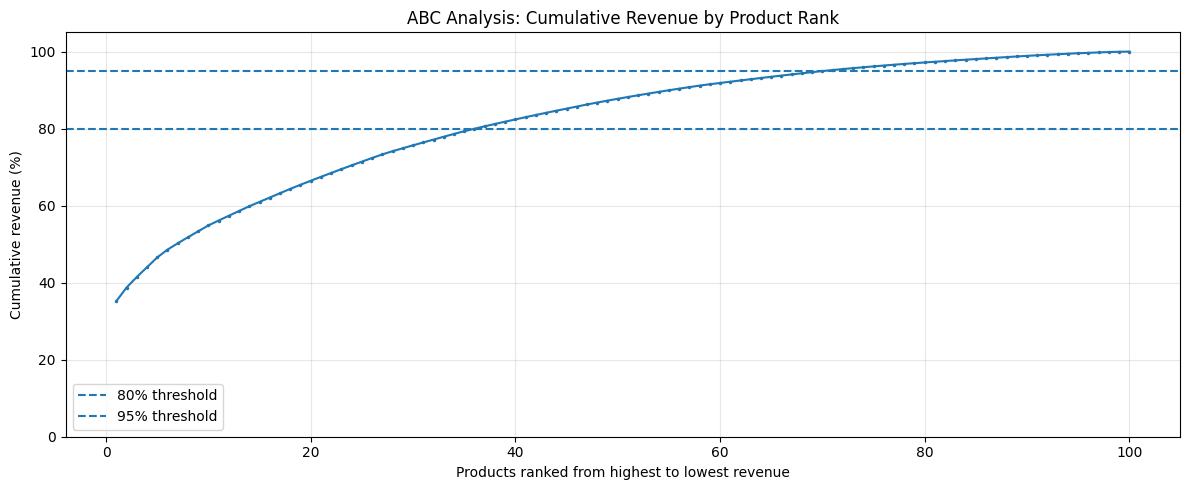

In [ ]:
# Pareto-style cumulative revenue chart
plt.figure(figsize=(12, 5))

plt.plot(
    range(1, len(df) + 1),
    df["Cumulative_Revenue_%"],
    marker=".",
    markersize=3
)

plt.axhline(y=80, linestyle="--", label="80% threshold")
plt.axhline(y=95, linestyle="--", label="95% threshold")

plt.title("ABC Analysis: Cumulative Revenue by Product Rank")
plt.xlabel("Products ranked from highest to lowest revenue")
plt.ylabel("Cumulative revenue (%)")
plt.ylim(0, 105)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


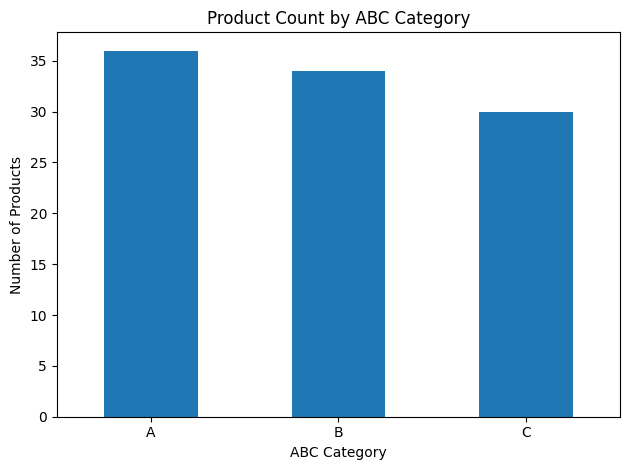

In [ ]:

abc_summary["Product_Count"].plot(
    kind="bar",
    title="Product Count by ABC Category",
    xlabel="ABC Category",
    ylabel="Number of Products"
)

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
